# 수수컴정 5주차 KOCOH EDA
자동화 담당 진군학의 노트북. 계산은 src/eda.py, 그림은 src/plotting.py, 분할은 src/preprocess.py에 있습니다.

## 오늘 확인할 네 가지
1. 결측은 어떤 열·Type에 모이는가? 입력을 사용할 수 있는가?
2. 길이와 반복은 어떤 구조인가? 제거해야 할 오류인가?
3. 클래스 불균형과 제작 유형은 평가와 입력에 어떤 영향을 주는가?
4. 분할은 어떤 누수를 막고 어떤 한계를 남기는가?

교수님 W5 91쪽의 순서에 따라 **질문과 WHY → 조건과 숫자 → 그림 → 관찰·해석 → 결정과 체크포인트**를 연결합니다. 연구 질문은 게시글 맥락을 추가하면 혐오표현 탐지가 개선되는가입니다. 이번에는 모델 학습·평가 전의 EDA만 수행합니다.

## 근거와 적용 범위
- [교수님 지시] W5 68쪽: 고정 조건에서 비교, 5회 반복 평균·SD 표, 영문 그림, 조건·지표 기록. 90~97쪽: 숫자 먼저, 결측 이유, 불균형, 분할·전처리 재현.
- [교수님 배포] W5_pretraining_solution.ipynb: 단계별 WHY와 체크포인트.
- [수업 중 에이전트 구현] bda-project의 w1_eda, w4_attention, w5_pretraining: 숫자 점검, 단위·가정·표본·실험조건 표시.
- [팀 보강] 공통 축·bin, 같은 색·해칭, PNG 300 dpi·벡터 PDF. 교수님의 dpi 요구라는 뜻은 아닙니다.

고정 CSV 빈도는 반복 실험이 아니므로 SD·신뢰구간 오차막대를 붙이지 않습니다. WSL Ubuntu-24.04의 ~/envs/research 커널에서 실행합니다. 원본이 없으면 프로젝트 루트에서 python -m src.download_data를 먼저 실행합니다.

## 0 준비와 분석 단위
**WHY:** 1행과 1개 게시글을 혼동하면 비율과 반복을 잘못 해석할 수 있습니다. 1행은 Context–Comment 쌍, Set은 게시글 번호입니다. Context는 게시글 요약 또는 대체 맥락이며 전문이 아닙니다. 동일 Context가 여러 댓글에서 반복된 행별 분포를 분석합니다.

In [1]:
SEED = 42
import sys
from pathlib import Path
print(sys.executable)
assert Path(sys.prefix).resolve() == (Path.home()/'envs/research').resolve(), 'research 커널을 선택하세요.'
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'src' / 'eda.py').exists()
sys.path.insert(0, str(ROOT))
from IPython.display import display, Image
from src.eda import analyze
from src.preprocess import load_data, model_inputs
summary, tables = analyze(verbose=False)
print('Rows:', summary['rows'], 'Columns:', summary['columns'], 'Sets:', summary['posts'], 'Removed rows:', summary['removed_rows'])

/home/jin/envs/research/bin/python


Rows: 3000 Columns: 18 Sets: 101 Removed rows: 0


## 1 결측은 어디에서 발생했는가
**WHY:** 전체 결측률만으로 삭제하면 대체 맥락 비교에 필요한 사례를 잃을 수 있습니다.

**조건:** 전체 3,000행 기준 결측과 빈 문자열을 먼저 표로 확인합니다. Figure 1(a)는 전체 행을, (b)는 각 Type의 행을 분모로 합니다. 원본 Source와 Set으로 출처를 대응한 파생 집계는 구별합니다.

,column,dtype,missing_count,missing_pct,unique_nonmissing,blank_count
0,Index,int64,0,0.000000,3000,0
1,Set,int64,0,0.000000,101,0
2,Type,int64,0,0.000000,3,0
3,Date,str,764,25.466667,36,0
4,Source,str,764,25.466667,2,0
5,Link,str,764,25.466667,101,0
6,Title,str,764,25.466667,101,0
7,Context,str,0,0.000000,282,0
8,Comment,str,0,0.000000,2174,0
9,Hate speech,int64,0,0.000000,2,0


,column,min,max
0,Index,1,3000
1,Set,1,101
2,Type,1,3
3,Hate speech,0,1
4,Counter speech,0,1
5,Gender,0,1
6,Disability,0,1
7,Race/Nationality,0,1
8,Region (Korea),0,1
9,Age,0,1


,source,rows
0,디시인사이드,1453
1,에펨코리아,783
2,미기재 (Type 2),764


,source,rows
0,디시인사이드,1981
1,에펨코리아,1018
2,NaN,1


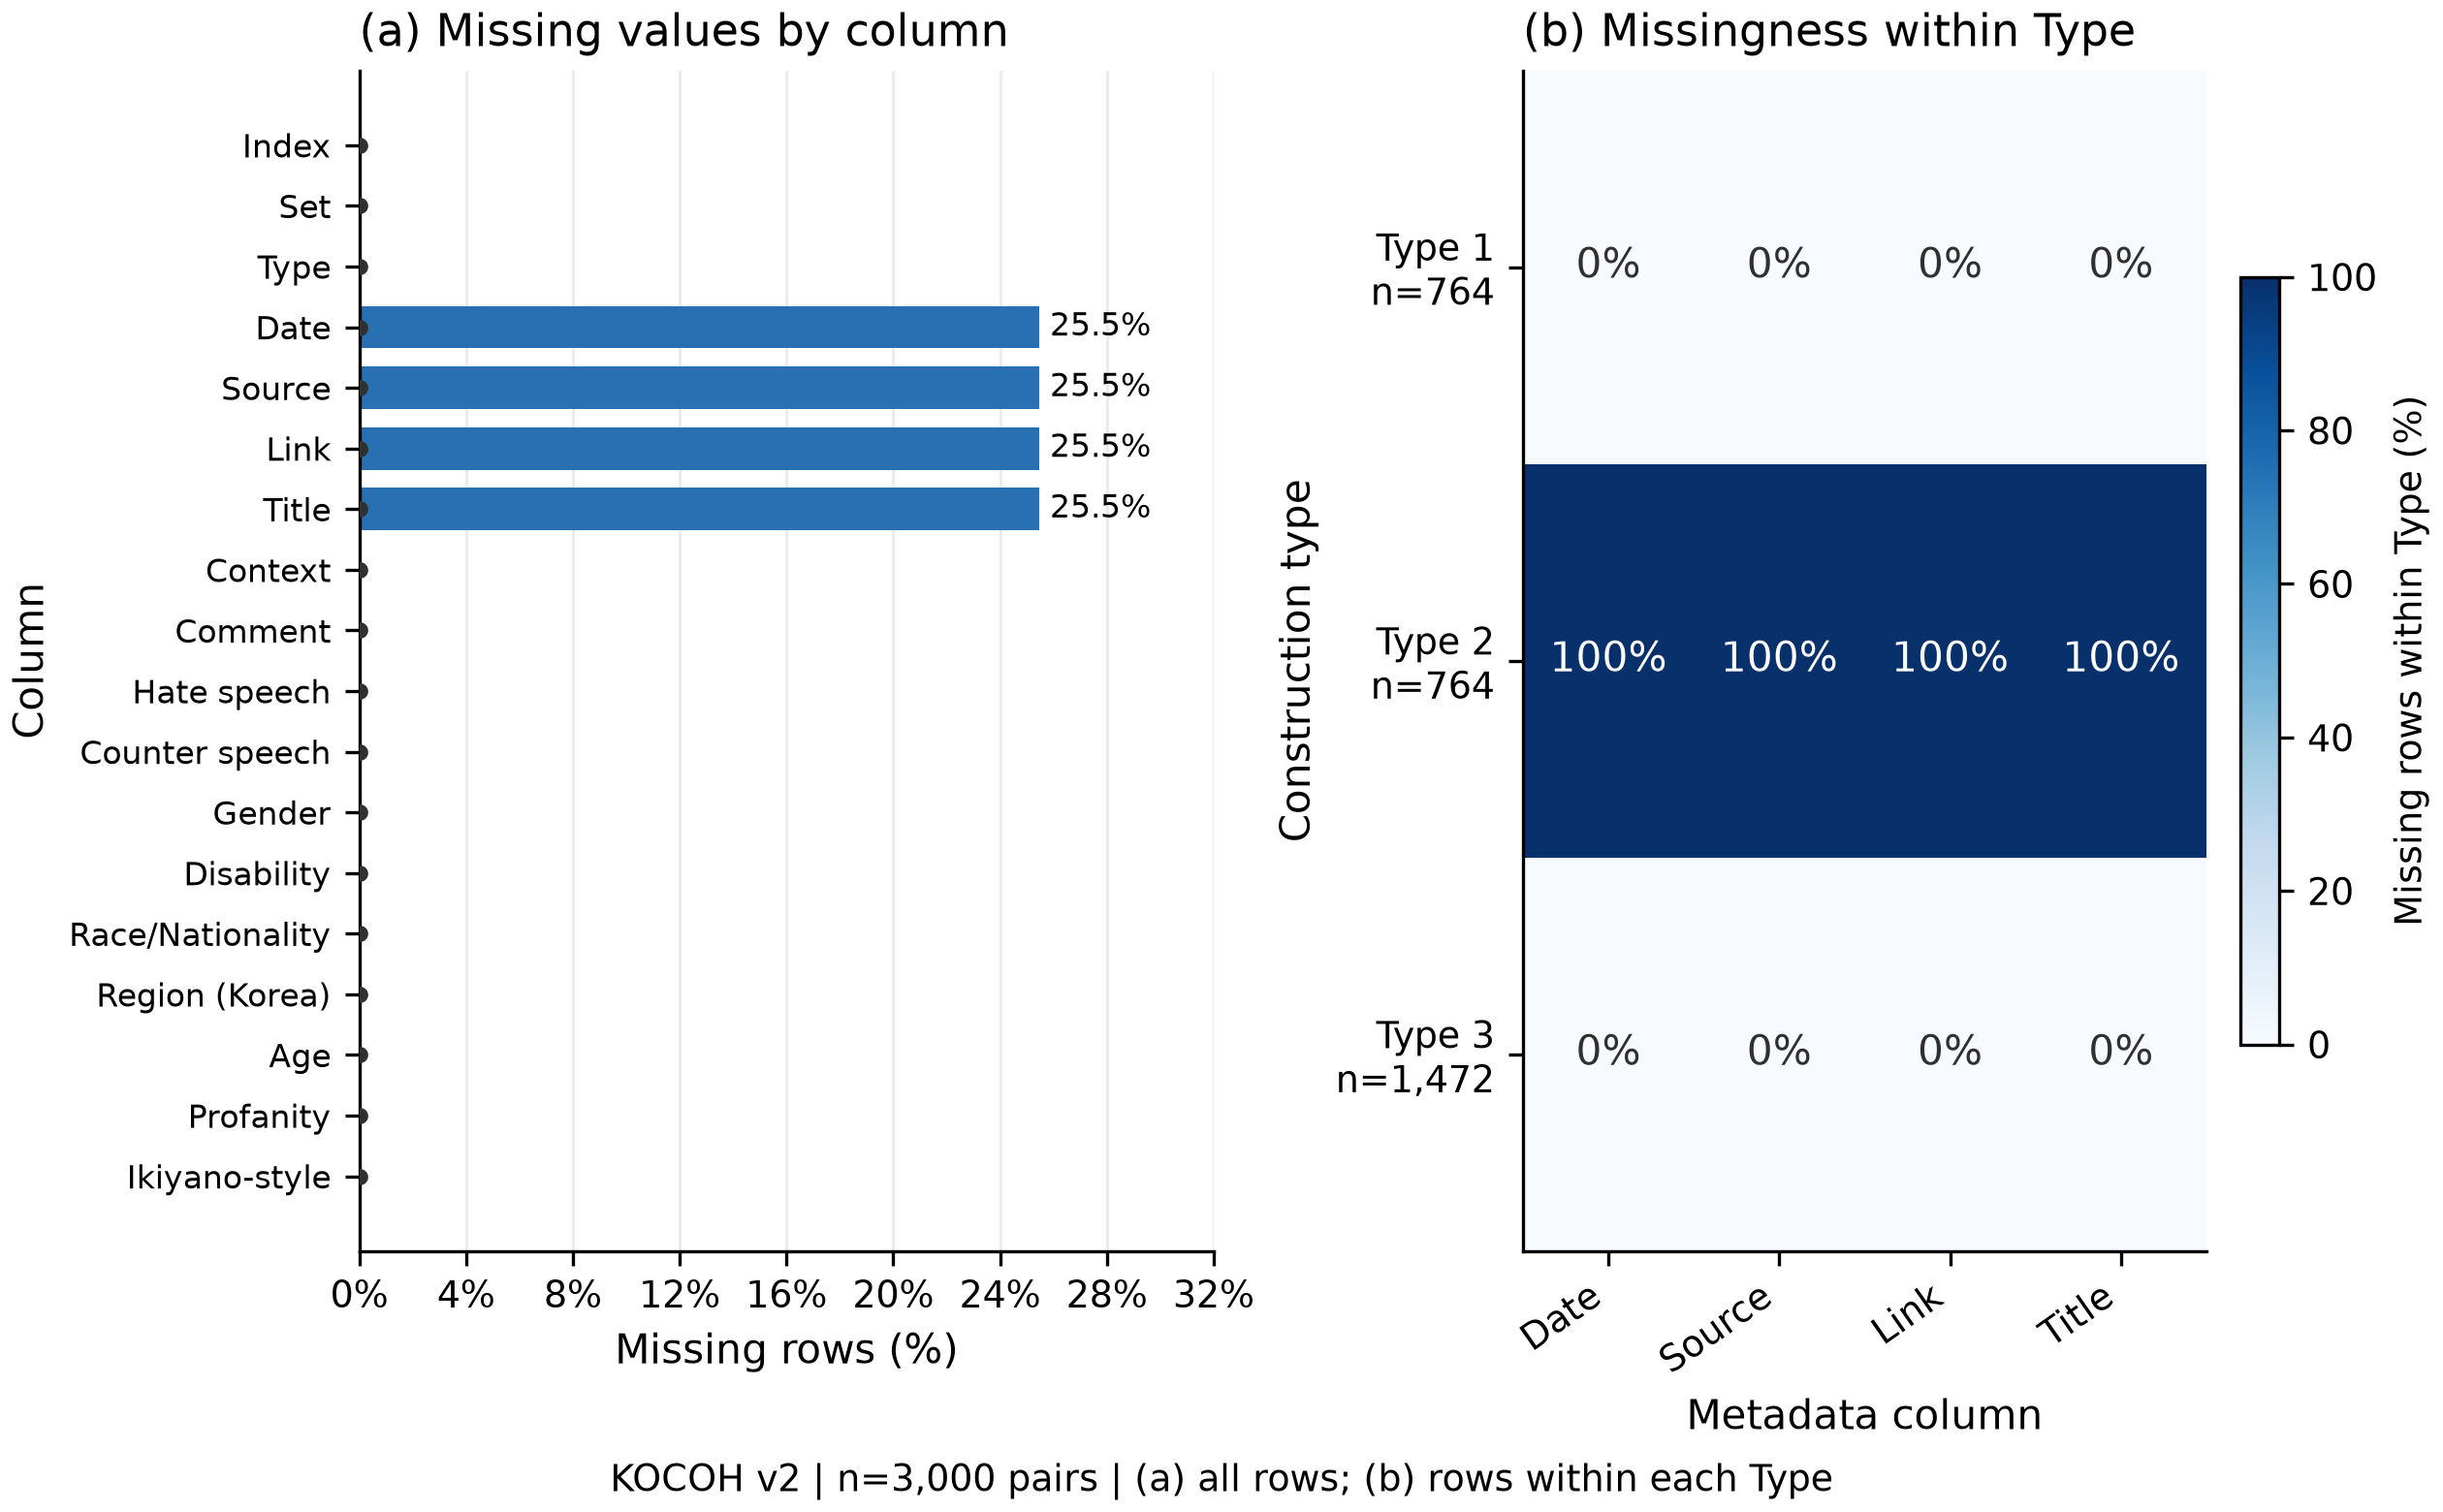

In [2]:
display(tables['column_profile']); display(tables['numeric_ranges']); display(tables['source_raw']); display(tables['source_parent_attributed'])
display(Image(filename=str(ROOT/'figures/01_missingness.png')))

**Figure 1. 열별 및 Type별 결측률.** 전체 분모에서는 출처 네 열 각각 25.47%이고, Type 2 내부에서는 100%입니다. 히트맵 색 범위는 0~100%입니다.

- **관찰:** Date·Source·Link·Title 각 764건이 비며 모두 Type 2입니다. Context·Comment·정답의 결측은 0입니다.
- **해석:** 대체 맥락 생성 방식에 따른 출처 결측과 일치하며 입력이 없는 경우와 다릅니다.
- **결정:** 삭제 0행. 파생 출처는 1,981/1,018/미확인 1행으로 따로 기록합니다. 논문과 다른 1행을 임의 배정하지 않습니다.
- **체크포인트:** 25.47%와 100%가 동시에 맞는 이유를 분모로 설명하세요.

## 2 값의 분포와 반복은 오류인가
**WHY:** 길거나 반복된다고 제거하면 맥락 비교라는 연구 목적을 해칠 수 있습니다.

**조건:** 문자 수와 공백 단위 수를 구별합니다. Figure 3은 두 패널에서 10문자 bin, 동일 x·y축, 3,000행 기준 백분율을 사용합니다. 문자 수는 모델 토큰 수가 아닙니다.

,measure,count,mean,std,min,50%,90%,95%,99%,max
0,Context_chars,3000.0,49.863000,19.858475,15.0,49.0,80.0,85.0,136.0,136.0
1,Context_whitespace_units,3000.0,12.053333,4.881164,4.0,12.0,17.0,21.0,33.0,33.0
2,Comment_chars,3000.0,18.541000,23.781088,1.0,13.0,37.0,49.0,101.0,400.0
3,Comment_whitespace_units,3000.0,4.384667,4.835200,1.0,3.0,9.0,12.0,21.0,81.0


Context_chars             Context_whitespace_units             \
               min median  max                      min median max   
Type                                                                 
1               18   52.0  136                        4   12.0  33   
2               15   40.0   99                        4   10.0  22   
3               18   49.0  136                        4   12.0  33   

     Comment_chars             Comment_whitespace_units             
               min median  max                      min median max  
Type                                                                
1                1   10.0  400                        1    2.0  81  
2                1   10.0  400                        1    2.0  81  
3                1   18.0  288                        1    4.0  67

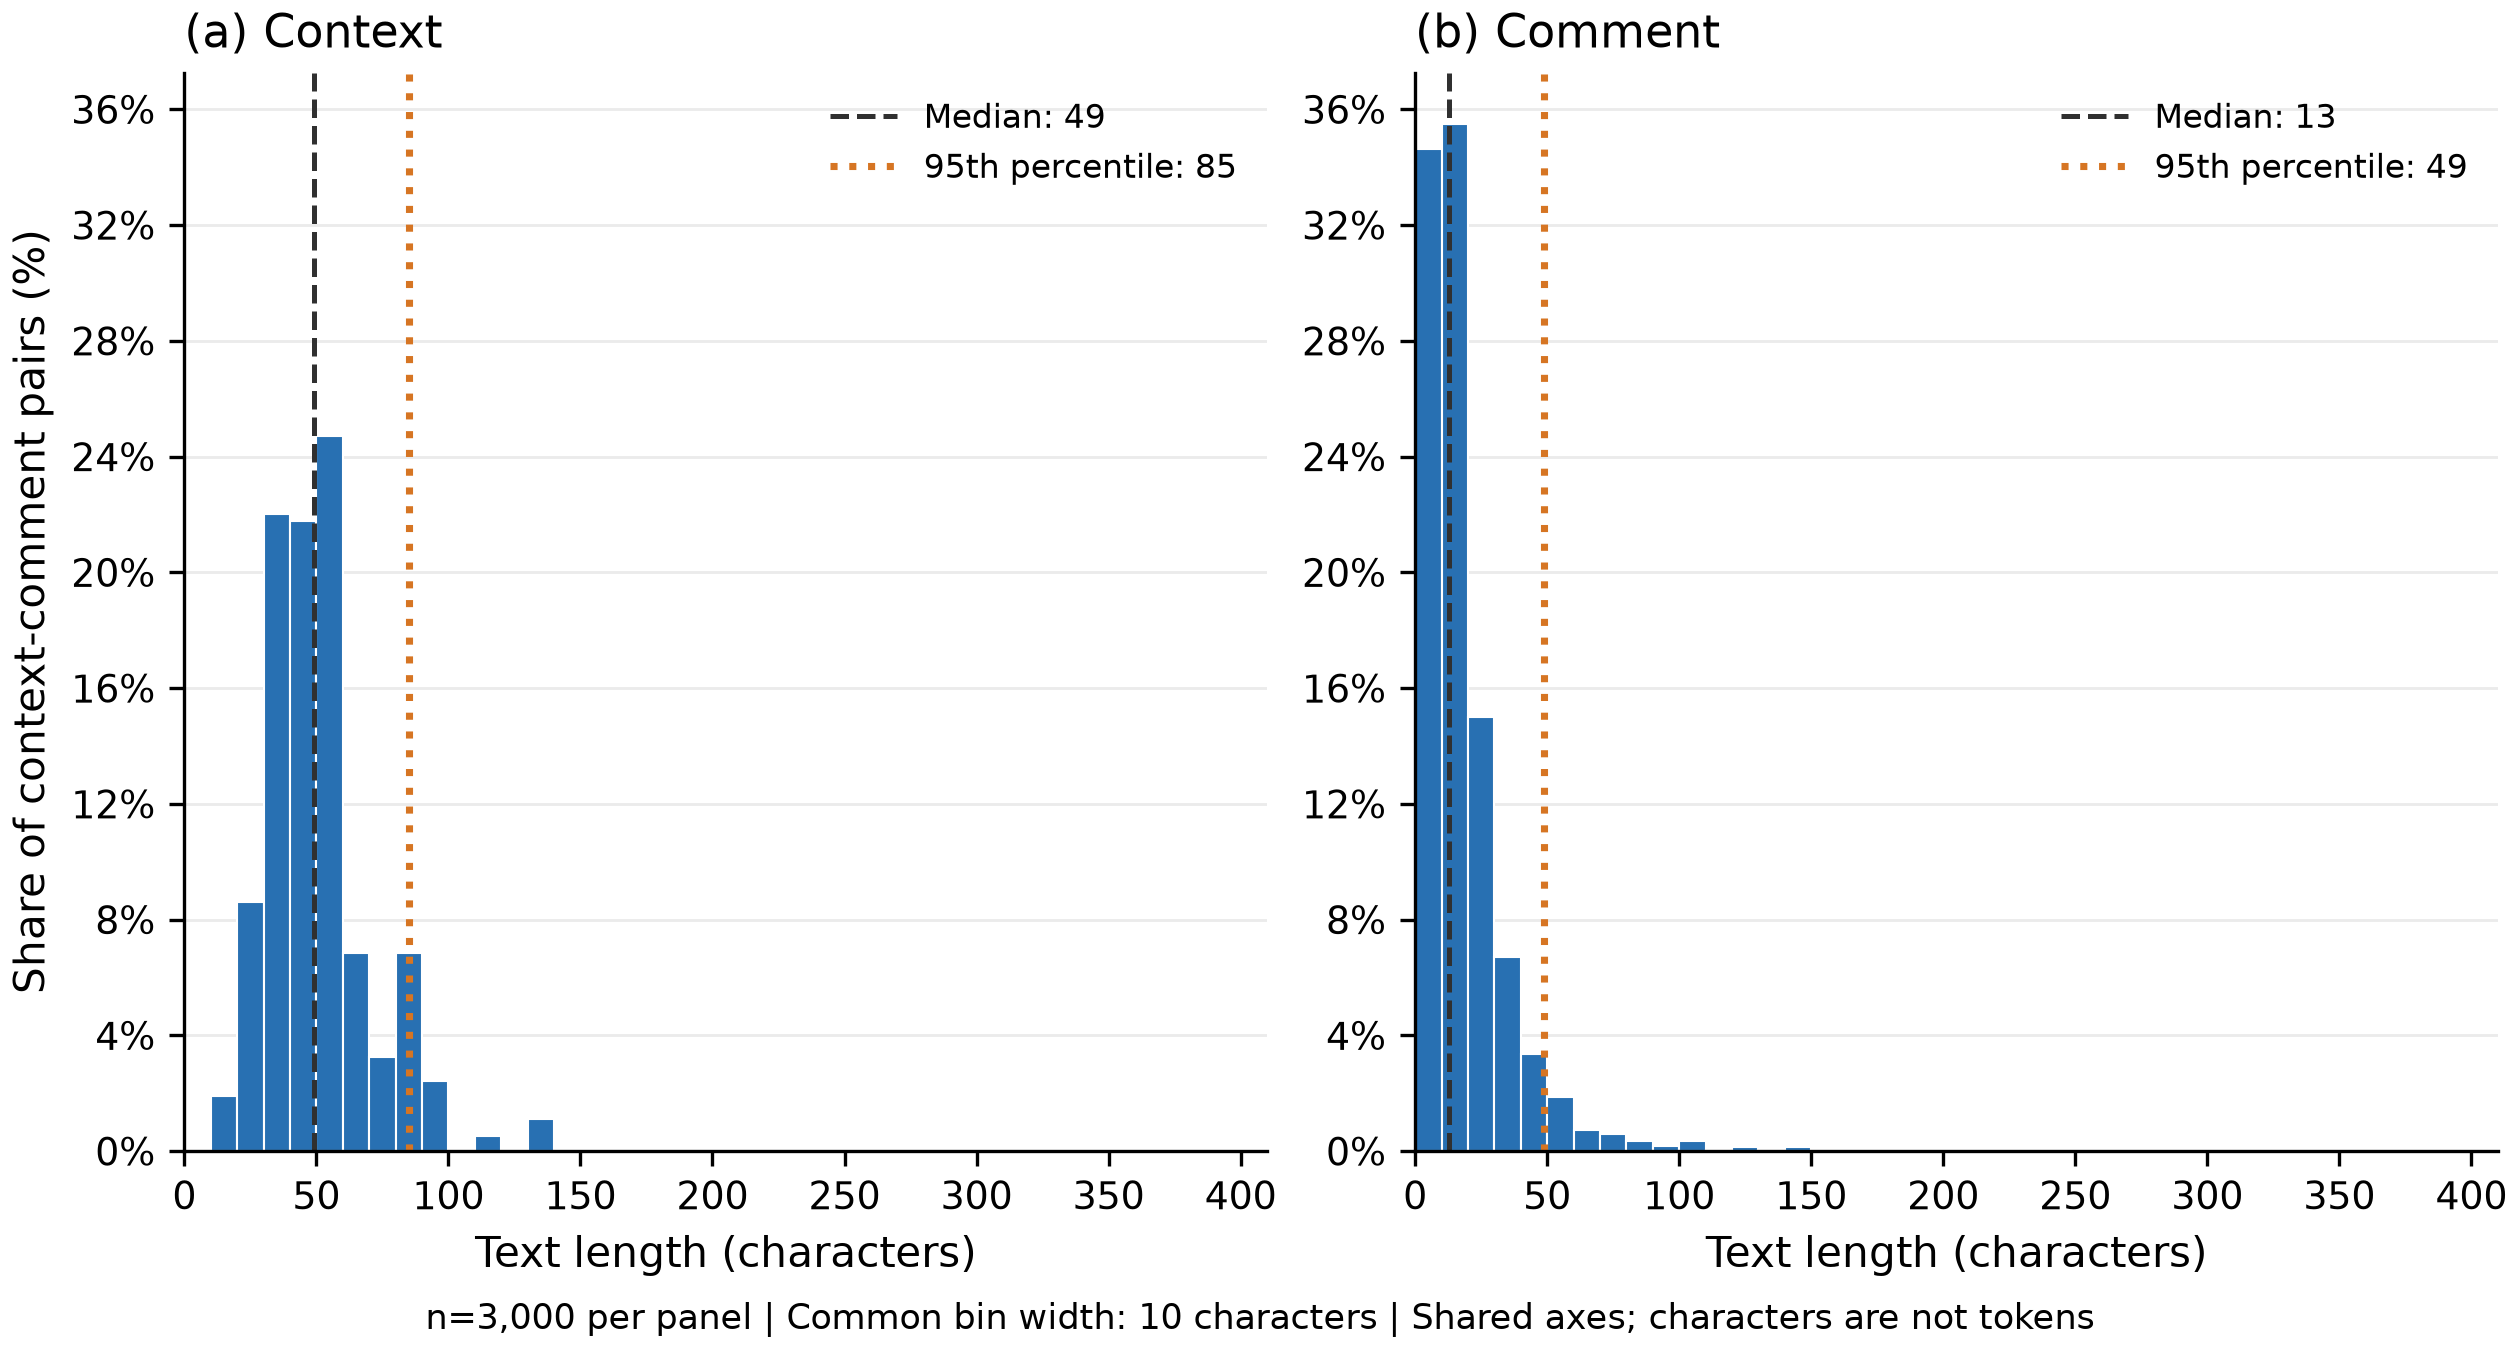

In [3]:
display(tables['text_lengths']); display(tables['lengths_by_type'])
display(Image(filename=str(ROOT/'figures/03_text_lengths.png')))

**Figure 3. Context와 Comment 문자 수 분포.** 회색 파선은 중앙값, 주황 점선은 95백분위입니다. 최댓값 400문자까지 포함하며 꼬리를 자르지 않았습니다. Context가 여러 행에서 반복된 행 단위 분포입니다.

- **관찰:** Context 중앙값 49·최대 136, Comment 중앙값 13·최대 400입니다. 날짜 범위는 2024-06-02~2025-01-21, 파싱 실패 0건입니다.
- **해석:** 댓글은 짧은 값에 집중하지만 긴 꼬리도 존재합니다. 길이만으로 오류를 판정할 수 없습니다. 식별자 Index·Set의 평균은 측정값처럼 해석하지 않습니다.
- **결정:** 자르기·기호 제거·불용어 삭제를 하지 않습니다. 모델 선정 뒤 train/valid의 실제 토큰 길이와 잘림을 확인합니다.
- **체크포인트:** 400문자가 400토큰을 뜻하지 않으며, 최대 문자 수만으로 입력 제한을 정할 수 없습니다.

In [4]:
import pandas as pd
display(pd.DataFrame([{'점검':k,'값':summary[k]} for k in ['comments_with_multiple_labels','duplicate_pair_excess_rows','conflicting_exact_pair_groups','duplicate_rows_excluding_index']]))

,점검,값
0,comments_with_multiple_labels,710
1,duplicate_pair_excess_rows,6
2,conflicting_exact_pair_groups,0
3,duplicate_rows_excluding_index,1


**관찰:** 다른 라벨이 붙는 동일 댓글은 710종이지만 동일 Context–Comment 쌍의 라벨 충돌은 0그룹입니다. 동일 두 입력쌍의 추가 중복은 6행입니다. **해석:** 댓글 중복과 두 입력쌍 중복은 다릅니다. **결정:** 같은 댓글을 자동으로 제거하지 않고 원본을 유지하며 반복 구조를 보고합니다.

## 3 불균형은 평가에 어떤 영향을 주는가
**WHY:** 정확도에 해석 가능한 기준선을 두고 정답을 드러내는 열이 입력에 섞이지 않게 합니다.

**조건:** 주 정답은 Hate speech(0/1), 전체 분모는 3,000행입니다. 부가 혐오 대상은 다중 라벨이므로 비율 합을 100%라고 해석하지 않습니다.

Hate speech,Type,0,1
0,1,0,764
1,2,764,0
2,3,1472,0


,target,positive_rows,pct_of_hate_rows
0,Gender,370,48.429319
1,Disability,23,3.010471
2,Race/Nationality,199,26.047120
3,Region (Korea),215,28.141361
4,Age,79,10.340314


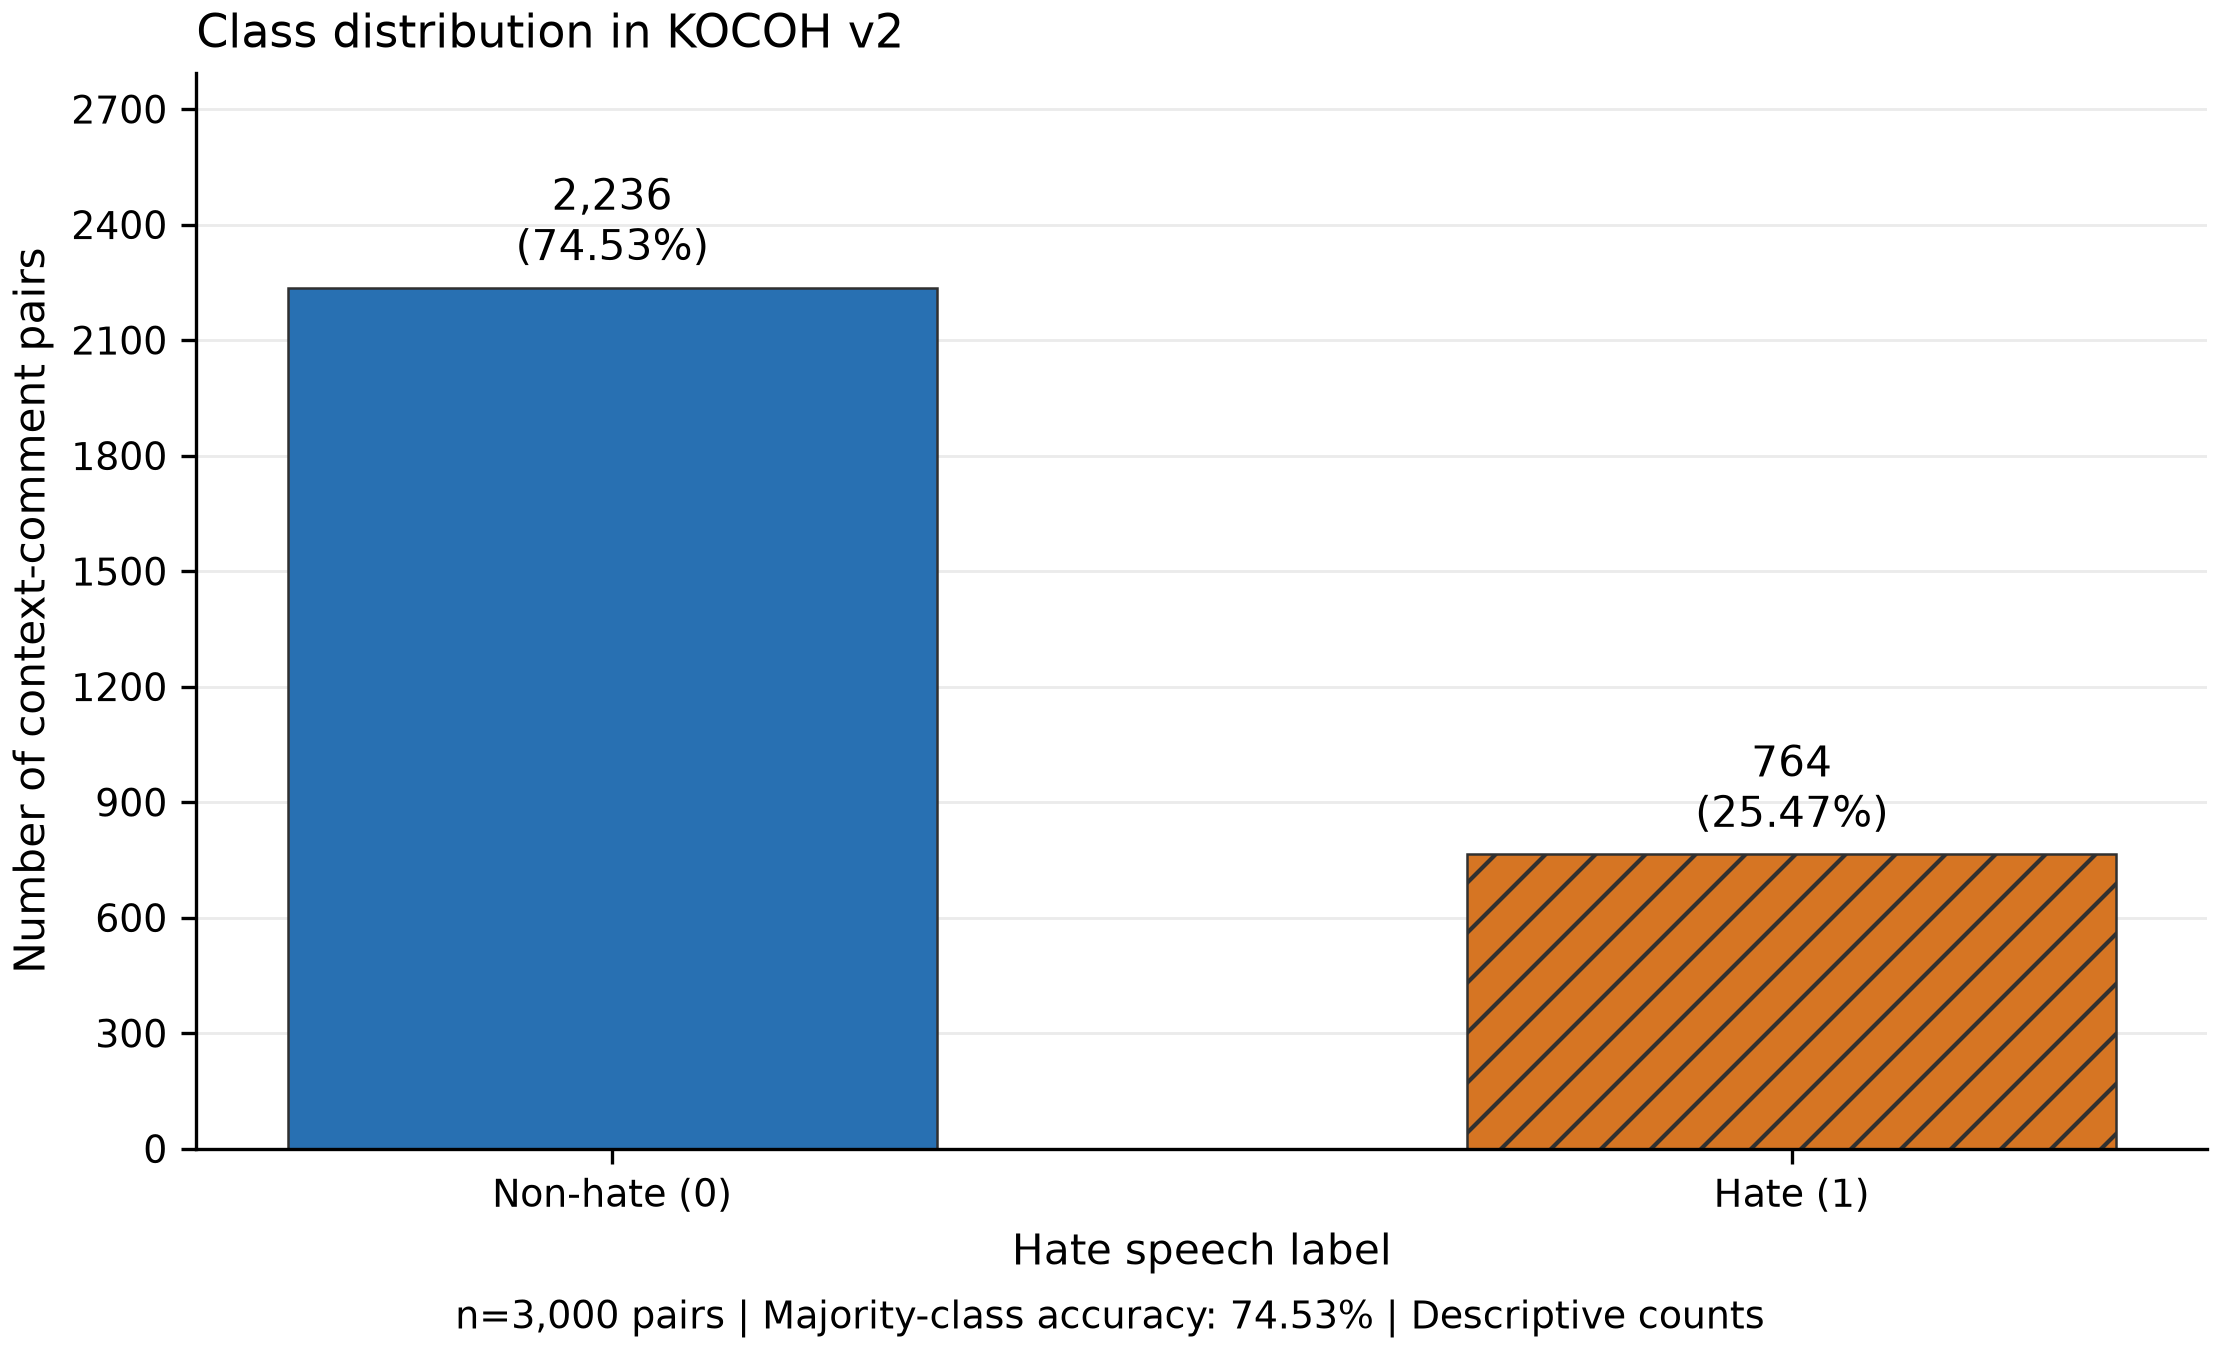

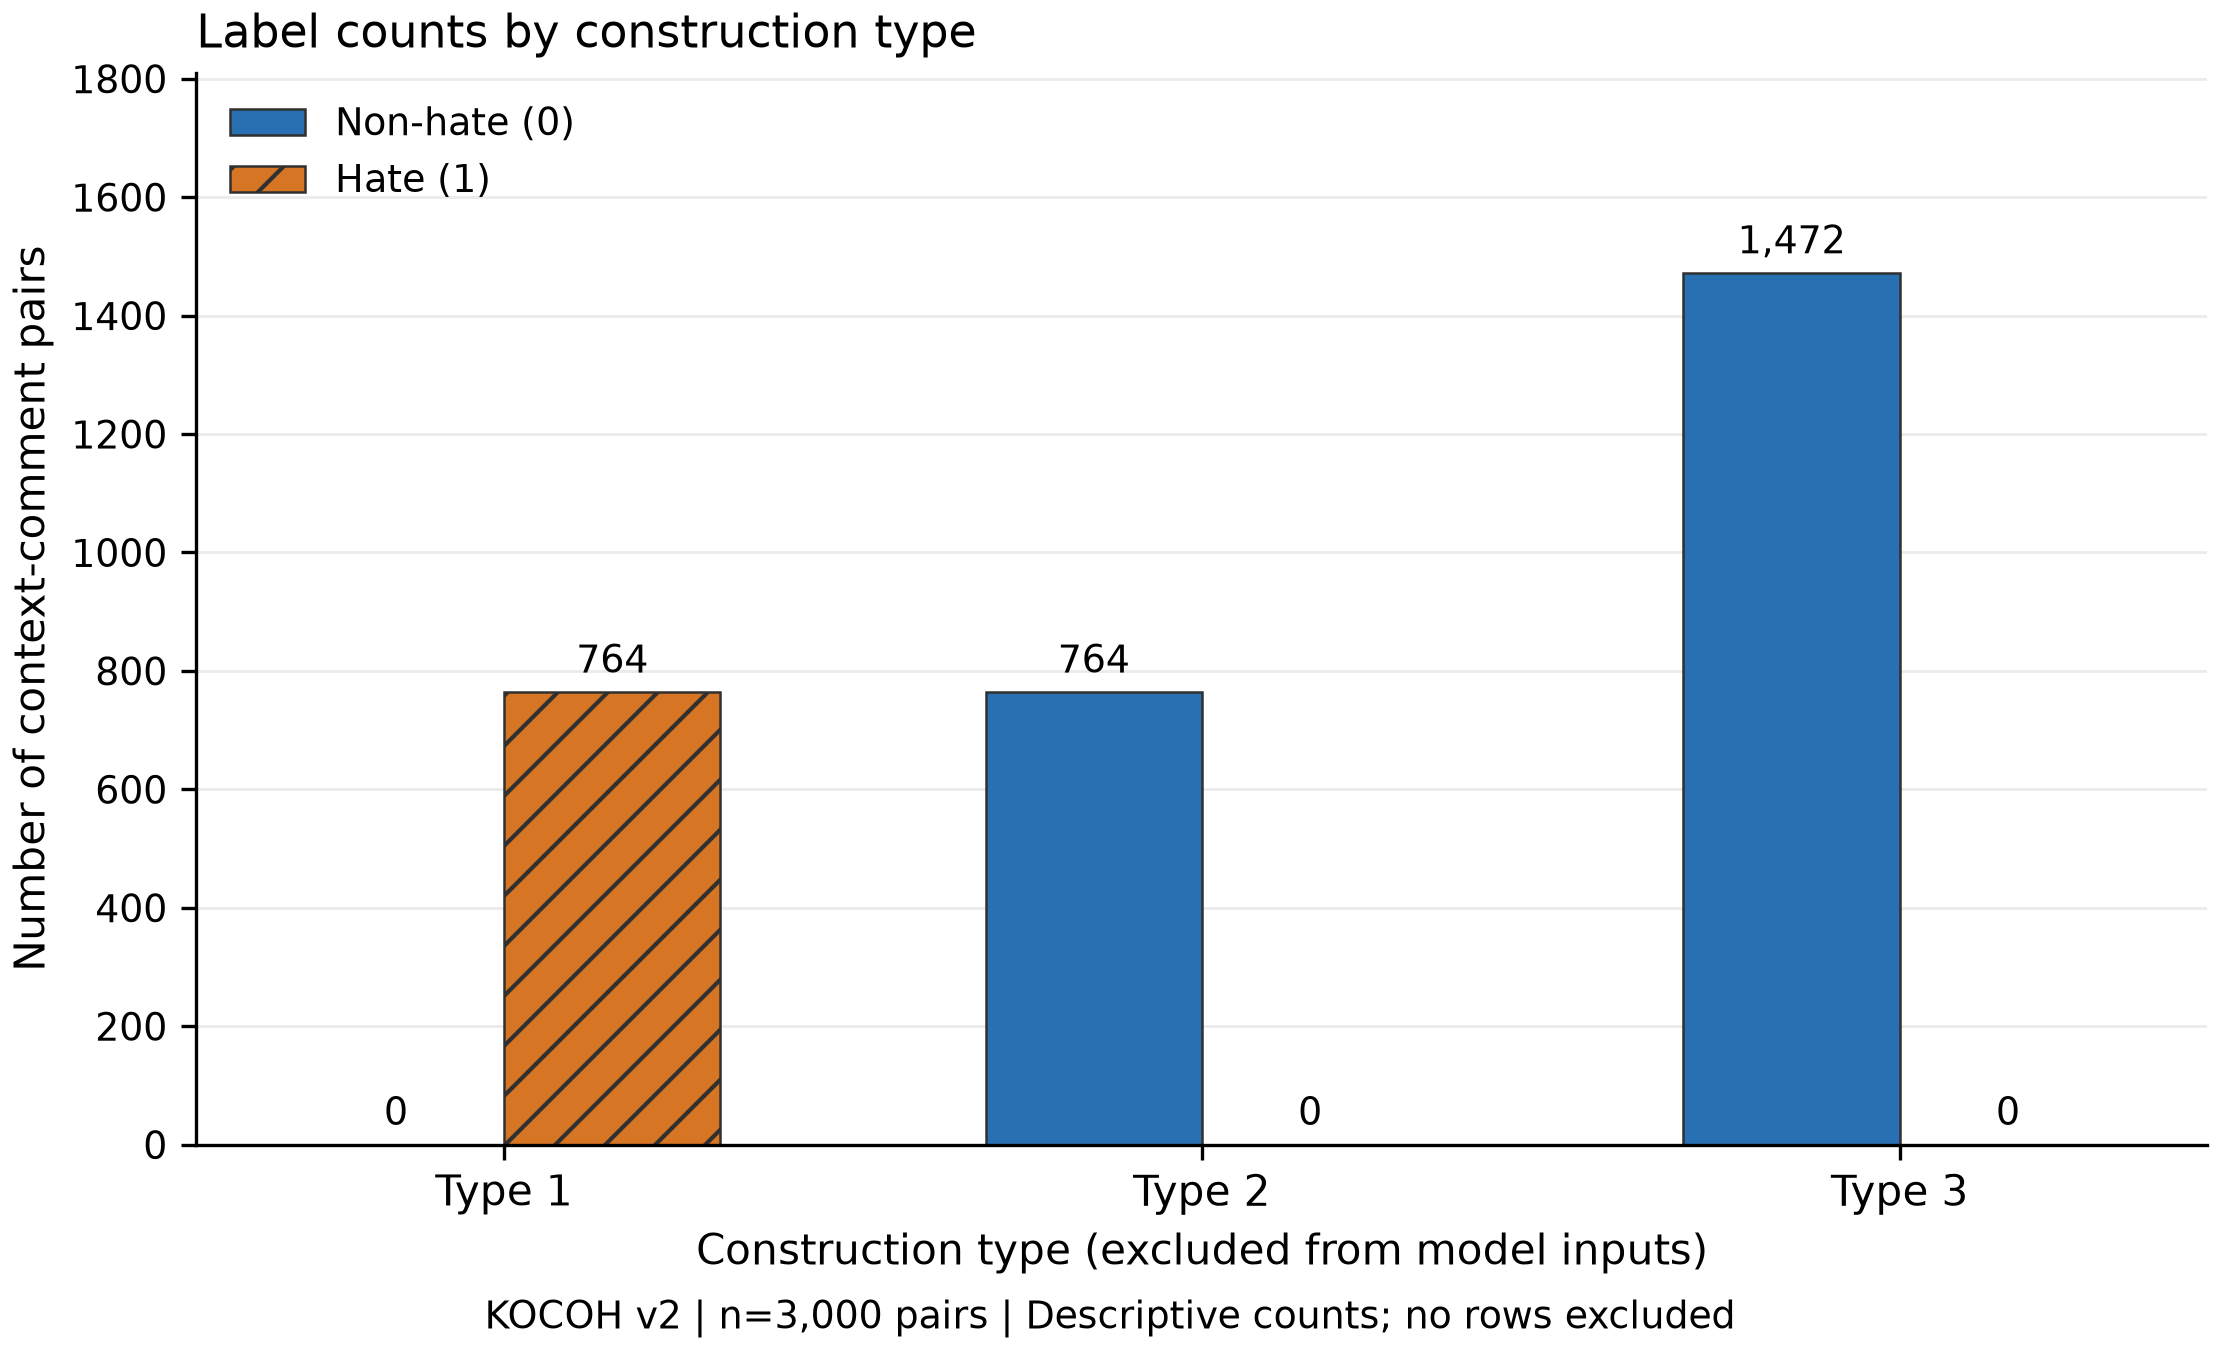

In [5]:
display(tables['type_label']); display(tables['target_labels'])
display(Image(filename=str(ROOT/'figures/02_class_balance.png')))
display(Image(filename=str(ROOT/'figures/04_type_labels.png')))

**Figure 2. 전체 라벨 빈도. Figure 4. Type별 라벨 빈도.** 두 그림은 파랑=비혐오, 주황 해칭=혐오를 공유합니다. 막대는 0에서 시작하며 개수를 표시합니다. 오차막대가 없는 기술통계입니다.

- **관찰:** 혐오 764행(25.47%), 비혐오 2,236행(74.53%). Type 1은 모두 혐오, Type 2·3은 모두 비혐오입니다.
- **해석:** 모두 비혐오 예측 시 정확도 74.53%지만 혐오 재현율·F1은 0입니다. 양성 예측이 없는 정밀도는 정의되지 않아 코드에서는 0으로 표기합니다.
- **결정:** 혐오 F1·정밀도·재현율·정확도를 함께 보고하며, Type과 부가 정답 주석을 입력에서 제외합니다. 시험 분할의 기준선은 그 분할에서 따로 계산합니다.
- **체크포인트:** 이 그림은 맥락 추가의 성능 향상을 입증한 실험 결과가 아닙니다. 개선 폭의 성공 기준은 아직 미정입니다.

## 4 분할은 어떤 위험을 줄이고 무엇을 남기는가
**WHY:** 모델과 입력 조건의 공정한 비교를 위해 평가 대상을 고정해야 합니다.

**조건:** StratifiedGroupKFold(5, shuffle=True, random_state=42), groups=Set, y=Hate speech. fold 0=test, fold 1=valid, 나머지=train. 원본 순서·버전·기존 분할을 유지합니다. 원논문의 공식 분할이 아닌 팀의 지도학습 설계입니다.

In [6]:
display(tables['split_summary']); display(tables['split_type']); display(tables['split_overlap']); display(tables['type12_set_exceptions'])

,split,rows,posts,nonhate,hate,hate_pct
0,train,1770,61,1325,445,25.141243
1,valid,639,21,471,168,26.291080
2,test,591,19,440,151,25.549915


Type,split,1,2,3
0,test,151,152,288
1,train,445,444,881
2,valid,168,168,303


,split_a,split_b,field,shared_unique_values,affected_rows_a,affected_rows_b
0,train,valid,Set,0,0,0
1,train,valid,Context,9,115,43
2,train,valid,Comment,14,40,33
3,train,valid,Context+Comment,1,1,1
4,train,test,Set,0,0,0
5,train,test,Context,4,11,39
6,train,test,Comment,12,36,28
7,train,test,Context+Comment,2,2,2
8,valid,test,Set,0,0,0
9,valid,test,Context,6,12,27


,Index,Set,Type,split
0,1500,43,1,train
1,1501,44,2,test


- **관찰:** 학습/검증/시험 1,770/639/591행, Set 중복 0. 학습·시험 사이 동일 입력쌍은 2개입니다. Index 1500·1501은 댓글 P가 같지만 Set 43·44여서 학습·시험에 나뉩니다.
- **해석:** Set 분할은 모든 반복 텍스트를 제거하지 않습니다. 원본 오류라고 단정하지 않습니다.
- **결정:** 원본과 분할은 유지하고, 학습 전에 예외·반복 입력과 민감도 분석 기준을 팀이 검토합니다.
- **체크포인트:** 성능을 본 뒤 seed나 분할을 바꾸지 않습니다. 이번에는 전체 구조만 점검했고 시험 예측·오류·점수는 보지 않았습니다.

## 5 모델 입력 인터페이스
전통적 분류기는 train 텍스트로 TF-IDF 어휘·IDF를 학습하고 valid/test에는 transform만 합니다. 사전학습 모델은 동일 분할에서 tokenizer의 text/text_pair 인터페이스를 사용합니다. 아래는 입력 열만 확인하며 텍스트 원문을 출력하지 않습니다.

In [7]:
data=load_data()
for condition in ['comment_only','context_comment']:
    X,y=model_inputs(data,condition)
    print(condition, 'input columns=',list(X),'rows=',len(X),'target=',y.name)

comment_only input columns= ['Comment'] rows= 3000 target= Hate speech
context_comment input columns= ['Context', 'Comment'] rows= 3000 target= Hate speech


## 판단과 다음 단계
- 완료: 원본 버전 고정, EDA 숫자·그림, Set 분할, 전처리 스크립트와 검증, 공유 문서.
- 게시 자료: [팀 Notion EDA](https://app.notion.com/p/5-KOCOH-EDA-3f70538d38d381d1b7c7c83e0d85889a) / [실험로그](https://app.notion.com/p/W5-KOCOH-3f70538d38d38159bc23f328c0c37732). 커밋 이력과 hook 설치는 저장소 README에서 확인한다.
- 다음: 모델 선택·실제 학습·성능 평가, tokenizer 기준 길이, 반복 입력과 Set 예외 검토, 주요 지표·성공 기준 확정.
- 기존 팀 Notion의 KcBERT·KcELECTRA와 macro-F1은 후보 메모다. 혐오 F1과 macro-F1의 정의를 구별하고 실제 실험 전에 주요 지표를 확인한다.
- 출처: 문제정의서, 데이터수집계획서, W5 강의자료 90~98쪽, KOCOH 논문 §3·4 및 공식 배포 설명.
